# **Deep Learning Lab Assignment 2**

This notebook compares neural networks with **6-4** and **12-8** hidden-layer configurations on Dataset 1.

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

_ = torch.manual_seed(0)

## **1. Read the data**

In [25]:
df = pd.read_csv("./data/Dataset1/train.csv")
df.head()

,x1,x2,label
0,-1.897355,-11.942014,0.0
1,-8.577827,-8.933562,0.0
2,12.233070,-7.865099,0.0
3,-9.509090,-0.342275,0.0
4,-7.933053,11.418172,1.0


In [26]:
df.shape

(1123, 3)

In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1123 entries, 0 to 1122
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      1123 non-null   float64
 1   x2      1123 non-null   float64
 2   label   1123 non-null   float64
dtypes: float64(3)
memory usage: 26.4 KB


In [28]:
df.describe()

,x1,x2,label
count,1123.000000,1123.000000,1123.000000
mean,-0.033283,-0.123244,0.490650
std,8.229637,8.750939,0.500135
min,-18.008298,-16.304481,0.000000
25%,-6.744575,-8.130018,0.000000
50%,0.034758,-0.048661,0.000000
75%,6.925826,7.313595,1.000000
max,18.447262,15.410218,1.000000


In [29]:
train_df = df
val_df = pd.read_csv("./data/Dataset1/val.csv")
test_df = pd.read_csv("./data/Dataset1/test.csv")

## **2. Prepare the data**

The training mean and standard deviation are used for all three splits.

In [30]:
feat_mean = train_df[["x1", "x2"]].mean()
feat_std = train_df[["x1", "x2"]].std()

In [31]:
def to_tensors(df):  # Prepare tensors
    X = (df[["x1", "x2"]] - feat_mean) / feat_std
    X = torch.tensor(X.values, dtype=torch.float32)
    y = torch.tensor(df["label"].values, dtype=torch.float32).view(-1, 1)
    return X, y

In [32]:
X_train, y_train = to_tensors(train_df)
X_val, y_val = to_tensors(val_df)
X_test, y_test = to_tensors(test_df)

X_train.shape, y_train.shape

(torch.Size([1123, 2]), torch.Size([1123, 1]))

## **3. Define the model**

The hidden layers use tanh and the output layer uses sigmoid.

In [33]:
# Two hidden layers
class MLP(nn.Module):
    def __init__(self, hidden1, hidden2):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, hidden1),
            nn.Tanh(),
            nn.Linear(hidden1, hidden2),
            nn.Tanh(),
            nn.Linear(hidden2, 1),
            nn.Sigmoid()
        )

    def forward(self, X):
        return self.network(X)

## **4. Train the model**

Pattern-mode learning updates the weights after each example. SGD uses $\eta=0.8$ and momentum $\alpha=0.9$. Three small error changes are required to avoid stopping on one noisy epoch, and gradients are clipped for stability.

In [34]:
def train_model(hidden1, hidden2, max_epochs=100):  # Train model
    model = MLP(hidden1, hidden2)
    loss_fn = nn.BCELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.8, momentum=0.9)
    train_errors, val_errors = [], []
    previous_error = None
    stable_epochs = 0

    for epoch in range(max_epochs):
        model.train()
        epoch_loss = 0.0

        # Pattern mode
        for index in torch.randperm(len(X_train)):
            X_one = X_train[index:index + 1]
            y_one = y_train[index:index + 1]
            optimizer.zero_grad()
            loss = loss_fn(model(X_one), y_one)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 0.1)  # Limit gradients
            optimizer.step()
            epoch_loss += loss.item()

        train_error = epoch_loss / len(X_train)

        # Validation error
        model.eval()
        with torch.no_grad():
            val_error = loss_fn(model(X_val), y_val).item()

        train_errors.append(train_error)
        val_errors.append(val_error)

        # Stable stop
        small_change = previous_error is not None and abs(previous_error - train_error) < 0.01
        stable_epochs = stable_epochs + 1 if small_change else 0
        previous_error = train_error

        if stable_epochs == 3:
            print(f"Stopped at epoch {epoch + 1}")
            break

    return model, train_errors, val_errors

## **5. Evaluation functions**

In [35]:
def accuracy(model, X, y):  # Find accuracy
    model.eval()
    with torch.no_grad():
        predictions = (model(X) >= 0.5).float()
    return (predictions == y).float().mean().item() * 100

In [36]:
def plot_decision_boundary(model, X, y, name):  # Plot boundary
    x1 = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200)
    x2 = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200)
    xx, yy = np.meshgrid(x1, x2)
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

    model.eval()
    with torch.no_grad():
        predictions = model(grid).reshape(xx.shape).numpy()

    plt.figure(figsize=(6, 4))
    plt.contourf(xx, yy, predictions, levels=[0, 0.5, 1], cmap="coolwarm", alpha=0.35)
    plt.scatter(X[:, 0], X[:, 1], c=y.squeeze(), cmap="coolwarm", edgecolors="black", s=15)
    plt.xlabel("Standardized x1")
    plt.ylabel("Standardized x2")
    plt.title(f"{name}: Decision Boundary")
    plt.show()

## **6. Compare both configurations**

### **Configuration 1: 6-4**

In [37]:
_ = torch.manual_seed(0)
model1, train_errors1, val_errors1 = train_model(6, 4)
train_acc1 = accuracy(model1, X_train, y_train)
val_acc1 = accuracy(model1, X_val, y_val)

print(f"Train accuracy: {train_acc1:.2f}%")
print(f"Validation accuracy: {val_acc1:.2f}%")

Stopped at epoch 86
Train accuracy: 97.60%
Validation accuracy: 96.21%


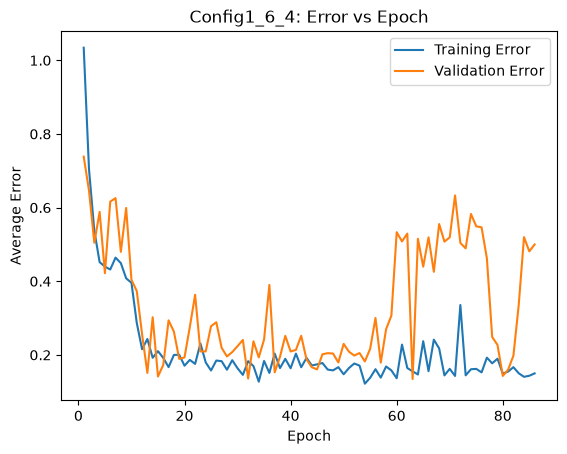

In [38]:
# Error plot
history1 = pd.DataFrame({"Training Error": train_errors1, "Validation Error": val_errors1})
history1.index += 1
history1.plot(title="Config1_6_4: Error vs Epoch", xlabel="Epoch", ylabel="Average Error")
plt.show()

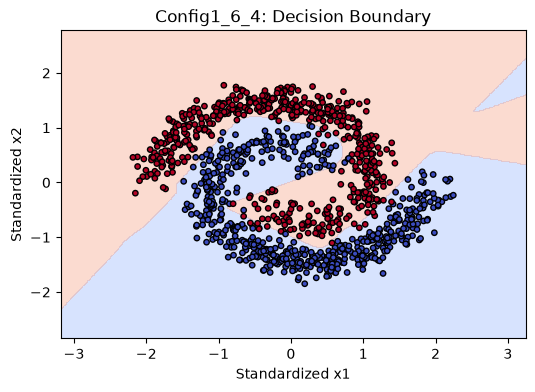

In [39]:
plot_decision_boundary(model1, X_train, y_train, "Config1_6_4")

### **Configuration 2: 12-8**

In [40]:
model2, train_errors2, val_errors2 = train_model(12, 8)
train_acc2 = accuracy(model2, X_train, y_train)
val_acc2 = accuracy(model2, X_val, y_val)

print(f"Train accuracy: {train_acc2:.2f}%")
print(f"Validation accuracy: {val_acc2:.2f}%")

Stopped at epoch 29
Train accuracy: 97.06%
Validation accuracy: 94.95%


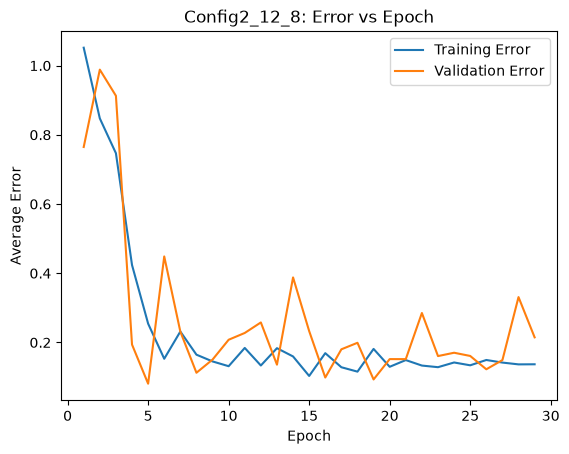

In [41]:
# Error plot
history2 = pd.DataFrame({"Training Error": train_errors2, "Validation Error": val_errors2})
history2.index += 1
history2.plot(title="Config2_12_8: Error vs Epoch", xlabel="Epoch", ylabel="Average Error")
plt.show()

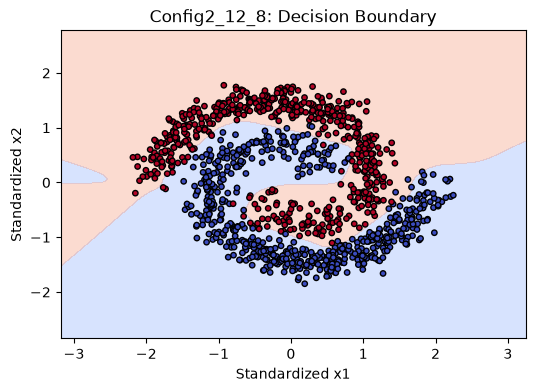

In [42]:
plot_decision_boundary(model2, X_train, y_train, "Config2_12_8")

In [43]:
results = {
    "Config1_6_4": {"model": model1, "train_acc": train_acc1, "val_acc": val_acc1},
    "Config2_12_8": {"model": model2, "train_acc": train_acc2, "val_acc": val_acc2}
}

## **7. Select and test the best model**

In [44]:
summary = pd.DataFrame(results).T[["train_acc", "val_acc"]]
summary.columns = ["Training Accuracy (%)", "Validation Accuracy (%)"]
summary.round(2)

,Training Accuracy (%),Validation Accuracy (%)
Config1_6_4,97.595727,96.214509
Config2_12_8,97.061443,94.952679


In [45]:
best_name = max(results, key=lambda name: results[name]["val_acc"])
best_model = results[best_name]["model"]
test_acc = accuracy(best_model, X_test, y_test)

print(f"Best configuration: {best_name}")
print(f"Test accuracy: {test_acc:.2f}%")

Best configuration: Config1_6_4
Test accuracy: 98.12%


## **Conclusion**

In [46]:
print(f"6-4 validation accuracy: {results['Config1_6_4']['val_acc']:.2f}%")
print(f"12-8 validation accuracy: {results['Config2_12_8']['val_acc']:.2f}%")
print(f"Selected model: {best_name}")
print(f"Final test accuracy: {test_acc:.2f}%")

6-4 validation accuracy: 96.21%
12-8 validation accuracy: 94.95%
Selected model: Config1_6_4
Final test accuracy: 98.12%
